# Argumentum : la carte de sophisme, du nœud de taxonomie à la carte jouable

La taxonomie Argumentum recense **1408 sophismes** (cf. `Argumentation-Onto-02-CrossLinks-CSV-Python.ipynb`).
Parmi eux, **175 sont sélectionnés comme cartes jouables** (colonne `carte=1`) : c'est le
*deck* imprimable du jeu Argumentum. Ce notebook montre comment **chaque carte dérive d'une ligne
de la taxonomie** — la carte est un nœud de l'arbre, et son contenu (nom, famille, description,
exemple, liens transverses) se construit mécaniquement depuis cette ligne.

**Lien avec l'EPIC #10355** : pour entraîner un modèle à détecter un sophisme, il faut d'abord
savoir *ce qu'il détecte*. La carte est l'unité pédagogique minimale : un nom, une définition,
un exemple. Ce notebook est le **rendu de référence** d'une carte depuis la source de données
canonique (la taxonomie bilingue), exploitable comme *golden answer* dans un jeu de données
de fine-tuning (Phase 2 de l'EPIC).

**Pré-requis** : aucune API externe, aucune clé. Le notebook lit la copie *in-repo* de la
taxonomie (`data/argumentum_fallacies_taxonomy.csv`, 1408 nœuds, bilingue FR/EN).

**Série Argumentation** | | Précédent : [02-Fallacies-Detection-Python](./Argumentation-02-Fallacies-Detection-Python.ipynb) | Suivant : [03-Dung-AF-Semantics-Python](./Argumentation-03-Dung-AF-Semantics-Python.ipynb) | [↑ Série Argumentation](README.md)

## 1. Chargement de la taxonomie et filtrage des cartes

On charge la taxonomie entière (1408 nœuds) puis on isole les 175 nœuds marqués `carte=1`.
La résolution du chemin CSV est robuste à l'exécution `nbconvert` (recherche de la racine du dépôt).

Le fichier `data/argumentum_fallacies_taxonomy.csv` est la **source canonique** de la taxonomie :
un nœud par ligne, **104 colonnes**, bilingue FR/EN (d'autres langues sont aussi présentes). Les
colonnes exploitées par ce notebook :

- **Hiérarchie** : `path` (ex. `1.3.2`, segments séparés par des points), `decimal_path`, `depth`
  (la profondeur = nombre de segments), `Famille`, `Sous-Famille` ;
- **Contenu de la carte** : `nom_vulgarisé` (nom FR), `Simple_name_en` (nom EN), `desc_fr` / `desc_en`
  (définitions), `example_fr` / `example_en` (exemples) ;
- **Liens transverses** : les 8 colonnes `crossLink_*` (`Denounces`, `PredatesOn`, `Opposes`, …) ;
- **Sélection** : la colonne `carte`, qui vaut `1` pour les 175 nœuds retenus comme cartes jouables.

Le fichier est lu en `utf-8-sig` (pour absorber le BOM) et `csv.DictReader` produit des
dictionnaires indexés par nom de colonne : c'est ce `row` que le rendeur de carte de la
section 3 consommera directement.

In [1]:
import csv
from pathlib import Path
from collections import Counter

def find_repo_root(start: Path) -> Path:
    for parent in [start, *start.parents]:
        if (parent / 'MyIA.AI.Notebooks').is_dir() and (parent / '.git').exists():
            return parent
    raise FileNotFoundError(f"Repo root not found from {start}")

REPO_ROOT = find_repo_root(Path.cwd())
CSV_PATH = REPO_ROOT / 'MyIA.AI.Notebooks' / 'SymbolicAI' / 'ArgumentAnalysis' / 'data' / 'argumentum_fallacies_taxonomy.csv'

with open(CSV_PATH, encoding='utf-8-sig') as f:
    TAXONOMY = list(csv.DictReader(f))

CARDS = [r for r in TAXONOMY if str(r.get('carte', '')).strip() not in ('', '0', 'False', 'false')]

print(f"Taxonomie entière   : {len(TAXONOMY)} nœuds")
print(f"Cartes jouables     : {len(CARDS)} (carte=1)")
print(f"Taux de sélection   : {100 * len(CARDS) / len(TAXONOMY):.1f} % des nœuds deviennent des cartes")
print(f"Source              : {CSV_PATH.name} ({CSV_PATH.stat().st_size / 1024:.0f} Ko)")

Taxonomie entière   : 1408 nœuds
Cartes jouables     : 175 (carte=1)
Taux de sélection   : 12.4 % des nœuds deviennent des cartes
Source              : argumentum_fallacies_taxonomy.csv (4085 Ko)


### Lecture du résultat : volumétrie de la taxonomie

La sortie confirme les chiffres annoncés en introduction : **1408 nœuds** au total, **175 cartes jouables** (`carte=1`), soit un taux de sélection de **12,4 %**, lus dans le fichier `argumentum_fallacies_taxonomy.csv` (**4079 Ko**).

## 2. Structure du deck : 7 familles représentées

Les 175 cartes couvrent **7 des 8 familles** canoniques de la taxonomie. La distribution est
intentionnellement équilibrée (~25 cartes par famille) pour que le deck soit jouable sans
qu'une famille domine.

La cellule suivante produit **deux panneaux** : à gauche, le nombre de cartes par famille (le
contenu du deck imprimé) ; à droite, le taux de sélection de chaque famille (cartes / nœuds
totaux), coloré en rouge quand la famille n'a aucune carte. C'est ce second panneau qui révèle
la famille exclue du deck.

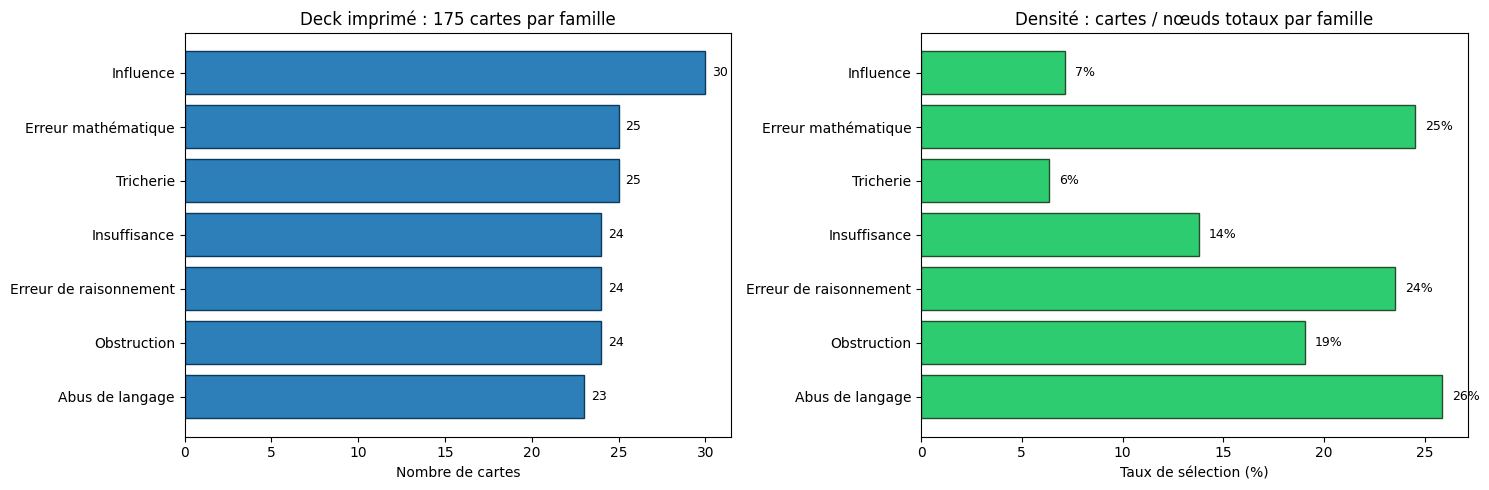

Familles avec cartes   : 7 / 8
Famille sans carte     : ['Argument fallacieux']


In [2]:
import matplotlib.pyplot as plt

fam_counts = Counter(r.get('Famille', '?') for r in CARDS)
fam_all = Counter(r.get('Famille', '?') for r in TAXONOMY)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Cartes par famille
fams = sorted(fam_counts.keys(), key=lambda k: -fam_counts[k])
axes[0].barh(fams, [fam_counts[f] for f in fams], color='#2c7fb8', edgecolor='#0c3a5b')
axes[0].set_xlabel('Nombre de cartes')
axes[0].set_title(f'Deck imprimé : {len(CARDS)} cartes par famille')
axes[0].invert_yaxis()
for i, f in enumerate(fams):
    axes[0].text(fam_counts[f] + 0.4, i, str(fam_counts[f]), va='center', fontsize=9)

# Taux de sélection par famille (cartes / total nœuds)
rates = [100 * fam_counts.get(f, 0) / fam_all.get(f, 1) for f in fams]
colors = ['#e74c3c' if fam_counts.get(f, 0) == 0 else '#2ecc71' for f in fams]
axes[1].barh(fams, rates, color=colors, edgecolor='#234d2b')
axes[1].set_xlabel('Taux de sélection (%)')
axes[1].set_title('Densité : cartes / nœuds totaux par famille')
axes[1].invert_yaxis()
for i, (f, rt) in enumerate(zip(fams, rates)):
    axes[1].text(rt + 0.5, i, f'{rt:.0f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

print(f"Familles avec cartes   : {sum(1 for f in fams if fam_counts.get(f,0)>0)} / 8")
print(f"Famille sans carte     : {[f for f in fam_all if fam_counts.get(f,0)==0] or 'aucune'}")

### Lecture du résultat : couverture des familles de cartes

La sortie texte annonce **7 familles sur 8** possédant au moins une carte, et nomme l'exception : **« Argument fallacieux »** est la seule famille sans carte jouable. La figure jointe présente les deux histogrammes : cartes par famille et taux de sélection par famille.

## 3. Le rendeur de carte : une carte = une ligne de taxonomie

La fonction `rendre_carte` prend une ligne de taxonomie et restitue le contenu d'une carte
Argumentum. Toute l'information affichée provient **exclusivement** de la ligne — rien n'est
inventé. Une carte contient : le nom vulgarisé (FR/EN), la famille, la profondeur dans
l'arbre, la définition, l'exemple, et les éventuels liens transverses (autres sophismes
que celui-ci dénonce ou préfigure).

Règles de rendu, lisibles directement dans la cellule de code :

- **Nom** : `nom_vulgarisé` en priorité, avec repli sur `text_fr` ; le nom anglais
  (`Simple_name_en`, repli `text_en`) n'est affiché entre parenthèses que s'il diffère du nom FR ;
- **Troncature** : la définition est coupée à 200 caractères et l'exemple à 180, suivis de `...`
  — une carte imprimable doit tenir sur un format carte ;
- **Profondeur** : affichée avec le `path` brut, ex. `path=1` ;
- **Liens transverses** : chaque colonne `crossLink_*` non vide est listée sous la forme
  `relation -> cible`.

La démonstration rend ensuite **3 cartes**, une par famille cible (`Insuffisance`, `Tricherie`,
`Influence`), pour montrer le gabarit sur des familles distinctes.

In [3]:
def rendre_carte(row: dict) -> str:
    """Rend une carte Argumentum depuis une ligne de taxonomie."""
    nom_fr = row.get('nom_vulgarisé', '').strip() or row.get('text_fr', '').strip()
    nom_en = row.get('Simple_name_en', '').strip() or row.get('text_en', '').strip()
    famille = row.get('Famille', '?')
    sous_fam = row.get('Sous-Famille', '').strip()
    profondeur = row.get('depth', '?')
    desc_fr = row.get('desc_fr', '').strip()
    desc_en = row.get('desc_en', '').strip()
    ex_fr = row.get('example_fr', '').strip()
    ex_en = row.get('example_en', '').strip()

    lignes = []
    lignes.append("=" * 64)
    lignes.append(f"  {nom_fr}".upper())
    if nom_en and nom_en.lower() != nom_fr.lower():
        lignes.append(f"  ({nom_en})")
    lignes.append("=" * 64)
    lignes.append(f"  Famille      : {famille}" + (f"  >  {sous_fam}" if sous_fam else ""))
    lignes.append(f"  Profondeur   : {profondeur} dans la taxonomie (path={row.get('path','')})")
    lignes.append("")
    lignes.append("  Définition (FR) :")
    lignes.append(f"    {desc_fr[:200]}{'...' if len(desc_fr)>200 else ''}")
    if desc_en:
        lignes.append("  Definition (EN) :")
        lignes.append(f"    {desc_en[:200]}{'...' if len(desc_en)>200 else ''}")
    if ex_fr:
        lignes.append("")
        lignes.append("  Exemple :")
        suffix_ex = '...' if len(ex_fr) > 180 else ''
        lignes.append(f'    "{ex_fr[:180]}{suffix_ex}"')
    # Liens transverses (crossLink_Denounces, crossLink_PredatesOn...)
    crosslinks = {k.replace('crossLink_', ''): row[k] for k in row
                  if k.startswith('crossLink_') and str(row[k]).strip()}
    if crosslinks:
        lignes.append("")
        lignes.append("  Liens transverses :")
        for rel, target in crosslinks.items():
            lignes.append(f"    - {rel} -> {target}")
    lignes.append("=" * 64)
    return "\n".join(lignes)

# Rendu de 3 cartes tirées de familles diverses
families_cibles = ['Insuffisance', 'Tricherie', 'Influence']
deja = set()
for fam in families_cibles:
    for r in CARDS:
        if r.get('Famille') == fam and r.get('path') not in deja:
            deja.add(r.get('path'))
            print(rendre_carte(r))
            print()
            break

  INSUFFISANCE
  (Insufficiency)
  Famille      : Insuffisance
  Profondeur   : 1 dans la taxonomie (path=1)

  Définition (FR) :
    Les arguments que vous utilisez ne suffisent pas à démontrer votre propos.
  Definition (EN) :
    The arguments used fail to provide adequate support for the conclusion.

  TRICHERIE
  (Cheating)
  Famille      : Tricherie
  Profondeur   : 1 dans la taxonomie (path=6)

  Définition (FR) :
    Vous vous affranchissez des règles tacites qui régissent un débat rationnel.
  Definition (EN) :
    Violating the norms of rational debate

  INFLUENCE
  Famille      : Influence
  Profondeur   : 1 dans la taxonomie (path=2)

  Définition (FR) :
    Vous manipulez votre auditoire pour le persuader au lieu de le convaincre.
  Definition (EN) :
    Using tactics to manipulate the audience rather than using logical reasoning.



### Lecture du résultat : rendu de trois cartes

Trois cartes sont rendues, une par famille cible : **Insuffisance** (`path=1`), **Tricherie** (`path=6`) et **Influence** (`path=2`), toutes de **profondeur 1**. Chacune présente le nom FR (et le nom EN entre parenthèses quand il diffère), la famille, la profondeur avec le `path`, et la définition bilingue — par exemple « Les arguments que vous utilisez ne suffisent pas à démontrer votre propos. » pour Insuffisance.

## 4. Carte et sous-arbre : la carte comme porte d'entrée

Une carte n'est pas une feuille de la taxonomie — c'est un **nœud**, souvent interne.
Ses **descendants** sont les sophismes plus spécifiques qu'elle regroupe. Pour la pédagogie
(et pour l'entraînement PT de l'EPIC #10355), c'est cette structure hiérarchique qui
justifie le workflow *« on part du général, et on descend dans l'arbre »*.

Exemple : la carte `Insuffisance` (path=`1`) a 3 enfants cartes (`Argument bâclé`,
`Préjugé`, `Surinterprétation`), chacun pouvant être à son tour raffiné.

Le `path` est la clé de cette hiérarchie : une chaîne de segments séparés par des points
(du nœud racine `1` jusqu'à la feuille, avec un segment de plus à chaque
niveau), et la profondeur d'un nœud est son nombre de segments. Un **enfant direct** d'un nœud de `path` `p` est donc un nœud de `path`
`p.<k>` — exactement ce que calcule `enfants_de` (un segment de plus, pas deux). L'affichage du
sous-arbre marque `[CARTE]` les nœuds sélectionnés dans le deck : on voit ainsi d'un seul coup
d'œil quelles branches de la taxonomie sont jouables.

In [4]:
def enfants_de(path: str, taxonomy: list) -> list:
    """Retourne les enfants directs d'un nœud (un segment de plus dans le path pointé)."""
    profondeur_parent = path.count('.') + 1
    res = []
    for r in taxonomy:
        p = r.get('path', '')
        if p.startswith(path + '.'):
            # enfant direct = exactement un segment de plus
            if p.count('.') == profondeur_parent:
                res.append(r)
    return res

def afficher_sous_arbre(path: str, taxonomy: list, max_prof=3, indent=0):
    """Affiche le sous-arbre d'un nœud (carte et ses descendants cartes)."""
    noeud = next((r for r in taxonomy if r.get('path') == path), None)
    if noeud is None:
        return
    nom = noeud.get('nom_vulgarisé', '') or noeud.get('text_fr', '')
    marque = '[CARTE]' if str(noeud.get('carte','')).strip() not in ('','0') else '       '
    print(f"{'  ' * indent}{marque} {nom}  (path={path})")
    if indent < max_prof:
        for enf in enfants_de(path, taxonomy):
            afficher_sous_arbre(enf.get('path'), taxonomy, max_prof, indent + 1)

# Sous-arbre de la carte 'Insuffisance' (path=1)
print("Sous-arbre de la carte 'Insuffisance' :")
print("(les [CARTE] sont les nœuds sélectionnés dans le deck imprimé)")
print()
afficher_sous_arbre('1', TAXONOMY, max_prof=3)

Sous-arbre de la carte 'Insuffisance' :
(les [CARTE] sont les nœuds sélectionnés dans le deck imprimé)

[CARTE] Insuffisance  (path=1)
  [CARTE] Argument bâclé  (path=1.1)
    [CARTE] Argument vide  (path=1.1.1)
              Appel à l’ignorance  (path=1.1.1.1)
              Appel à l’urgence pragmatique  (path=1.1.1.2)
              Acte de foi  (path=1.1.1.3)
              Pensée clichée  (path=1.1.1.4)
    [CARTE] Justification triviale  (path=1.1.2)
      [CARTE] Preuve anecdotique  (path=1.1.2.1)
      [CARTE] Pratique courante  (path=1.1.2.2)
      [CARTE] Sophisme du psychologue  (path=1.1.2.3)
    [CARTE] Sauvetage ad hoc  (path=1.1.3)
              Le marteau d’or  (path=1.1.3.1)
              Argument par le scénario  (path=1.1.3.2)
              Trouver des excuses  (path=1.1.3.3)
              Effet rebond  (path=1.1.3.4)
              Argument sorti de nulle part  (path=1.1.3.5)
  [CARTE] Préjugé  (path=1.2)
    [CARTE] Argument d’autorité  (path=1.2.1)
              Argum

### Interprétation : la carte comme unité pédagogique et cible d'entraînement

Le sous-arbre ci-dessus révèle la **double fonction** d'une carte Argumentum :

1. **Unité pédagogique autonome** : la carte se suffit à elle-même (définition + exemple),
   elle est jouable sans connaître ses descendants. C'est ce qui en fait un objet de deck.
2. **Racine d'un sous-arbre** : la carte pointe vers une famille de sophismes plus spécifiques.
   Pour le modèle entraîné (EPIC #10355, Phase 4 PostTraining), identifier la carte exacte
   n'est *pas* l'objectif — l'objectif est de **descendre dans l'arbre** jusqu'à la feuille
   précise que l'argument déployé exemplifie réellement. La carte est l'entrée du workflow,
   pas sa sortie.

C'est pourquoi un même exemple d'argument peut être *étiqueté* par plusieurs cartes de la
même branche : la carte racine (générale) et la carte feuille (spécifique) sont toutes deux
des réponses correctes, à des niveaux de granularité différents. Le jeu de données de FT
(Phase 3) devra distinguer ces niveaux pour ne pas pénaliser une réponse « juste mais moins
fine ».

## 5. Exercice : recherche de cartes par mot-clé

Implémentez une recherche qui, étant donné un mot-clé (ex. « émotion »), retourne les cartes
dont la définition ou l'exemple (FR ou EN) contient ce mot. Ce sera l'embryon de l'index
requis pour qu'un LLM puisse, depuis un argument, *retrouver* la branche de taxonomie
pertinente avant de descendre.

In [5]:
def chercher_cartes(mot_cle: str, cards: list) -> list:
    """Retourne les cartes dont desc_fr/desc_en/example_fr/example_en contient mot_cle.

    # Indice : cherchez dans les 4 champs textuels, insensible à la casse.
    # Etape 1 : normaliser mot_cle et les champs en minuscules.
    # Etape 2 : retourner la liste des cartes matchant au moins un champ.
    """
    # TODO etudiant
    return None  # à compléter

# Test rapide (décommenter après implémentation) :
# for c in chercher_cartes('émotion', CARDS):
#     print(rendre_carte(c))
#     print()

## 7.1. Exercice — compter les cartes par profondeur

**Objectif** : la sélection « carte » n'est pas une couche unique de la taxonomie. Produisez un décompte des cartes par niveau de profondeur (`depth`) pour montrer la **granularité hiérarchique** de la sélection — c'est exactement la structure que le PostTraining (Phase 2) doit exposer à un modèle de raisonnement pour qu'il sache qu'une carte profondeur 1 et une carte profondeur 4 ne représentent pas le même niveau de généralité.

**Indice** : la colonne `depth` du CSV est une chaîne de caractères ; pensez à la convertir en entier avant le décompte. `collections.Counter` est votre ami.

> **Indice : commencez par filtrer les cartes (carte=1), extrayez la colonne depth, comptez. :**
> **Etape 1 : créer une liste d'entiers depuis r['depth'] pour chaque carte. :**
> **Etape 2 : utiliser Counter() pour compter les occurrences par profondeur. :**

In [6]:
def compter_cartes_par_profondeur(cards: list) -> dict:
    """Retourne un dict {profondeur_int: nb_cartes} pour la sélection `cards`.

    # Indice : iter sur cards, convertir r['depth'] en int (skip si non numerique).
    # Etape 1 : initialiser un Counter vide.
    # Etape 2 : pour chaque carte, incrementer le Counter à la profondeur normalisée.
    # Etape 3 : retourner dict(sorted(counter.items())).
    """
    # TODO etudiant
    return None  # à compléter

In [7]:
# Démonstration attendue (à décommenter après votre implémentation) :
# distribution = compter_cartes_par_profondeur(CARDS)
# for prof, nb in sorted(distribution.items()):
#     print(f"  profondeur {prof} : {nb} cartes")

## 7.2. Exercice — remonter d'un sophisme feuille vers sa carte ancêtre

**Objectif** : l'inverse de l'exercice 5 (cellule 4 — *la carte ouvre un sous-arbre*). Le workflow descendant « carte → enfants → sophismes spécifiques » est ce que la cellule 9 illustre déjà via `afficher_sous_arbre`. La **remontée** « sophisme feuille → carte ancêtre » est l'opération symétrique dont la Phase 4 aura besoin pour transformer une détection en *contexte* : étant donné un sophisme identifié en bout de chaîne, on remonte à la carte qui l'a *catégorisé*, et c'est la carte qui devient l'unité pédagogique.

**Indice** : un path est une chaîne de segments séparés par des points (ex. `1.3.2.1`). Le parent d'un nœud est ce path privé de son dernier segment. La carte ancêtre est le premier ancêtre dont le path figure dans la sélection `cards`.

> **Indice : remonter iterativement d'un cran (parent = path.rsplit('.', 1)[0]). :**
> **Etape 1 : definir path_parent(p) qui retourne le parent ou '' si plus de parent. :**
> **Etape 2 : remonter en boucle jusqu'à trouver un path dans cards (set des paths cartes). :**
> **Etape 3 : retourner la ligne de taxonomie correspondante, ou None si pas d'ancêtre carte. :**

In [8]:
def carte_ancetre_feuille(path_feuille: str, taxonomy: list, cards: list) -> dict | None:
    """Remonte d'un nœud feuille jusqu'à la première carte ancêtre.
    Retourne la ligne de taxonomie de cette carte ancêtre, ou None si le chemin est
    orphelin (aucun ancêtre n'est une carte).

    # Indice : set(card['path'] for card in cards) => O(1) lookup à chaque remontée.
    # Etape 1 : construire l'ensemble des paths de cartes (pour lookup rapide).
    # Etape 2 : remonter en boucle : parent = path.rsplit('.', 1)[0].
    # Etape 3 : si parent vide (racine sans carte), retourner None.
    # Etape 4 : sinon retourner la ligne de taxonomy dont path == parent.
    """
    # TODO etudiant
    return None  # à compléter

In [9]:
# Démonstration attendue (à décommenter après votre implémentation) :
# # Trouve une feuille de profondeur >= 3 et remonte à sa carte ancêtre
# for r in TAXONOMY:
#     if str(r.get('carte','')).strip() in ('','0') and str(r.get('depth','')).isdigit() and int(r['depth']) >= 3:
#         ancetre = carte_ancetre_feuille(r['path'], TAXONOMY, CARDS)
#         if ancetre:
#             print(f"Feuille {r['path']}  ->  carte ancêtre {ancetre['path']}")
#             break

## 8. Conclusion et ponts

- **Une carte = une ligne de taxonomie** : le rendu est mécanique, reproductible, bilingue. Aucune information n'est inventée — tout provient du CSV canonique.
- **175 cartes sur 1408 nœuds** (12,4 %), réparties sur 7 familles, ~25 par famille.
- **La carte est un nœud interne** : elle ouvre un sous-arbre de sophismes spécifiques. C'est cette structure hiérarchique que le PostTraining (EPIC #10355) exploitera comme workflow.

**Ponts avec la série** :

- [`Argumentation-Onto-02-CrossLinks-CSV-Python.ipynb`](Argumentation-Onto-02-CrossLinks-CSV-Python.ipynb) — la taxonomie entière (1408 nœuds), sa structure, ses liens transverses.
- [`Argumentation-08e-Argument-Profile-Python.ipynb`](Argumentation-08e-Argument-Profile-Python.ipynb) — le profil multidimensionnel d'un argument dans un débat (5 dimensions, dont les sophismes).
- EPIC **#10355** — fallacy detection via Qwen3.5/3.6 FT+PT : ce notebook fournit le rendu de référence de la *golden answer* pour le jeu de données de fine-tuning.

*Données : Argumentum taxonomy (bilingue, 1408 nœuds). Notebook exécutable sans API ni clé.*
